# AGO1 × ATG8: PLIP contacts per CDD pocket vs candidate AIMs

Rows = every canonical `[WFY]xx[LIV]` window in AGO1 (O04379); aromatic residue *i* and aliphatic residue *i+3* are shown separately.
Columns = ATG8 isoform × CDD *peptide binding site 1 / 2*.
Cell value = number of ColabFold samples (0–5) in which that AGO1 residue makes a PLIP contact with ≥1 residue of the pocket.

**ATG8H (Q8S925) pockets are SYNTHETIC** (CDD finds no domain): transferred by alignment from ATG8A–G, see `notebooks/ago1_aim_atg8.py`.
ATG8I has no CDD peptide sites, so its columns are empty (annotation gap, not absence of binding).
Run `python notebooks/ago1_aim_atg8.py` first (writes `atg8_sites.parquet`).

In [1]:
import re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "results_ago1_autophagy_colabfold").exists(): ROOT = ROOT.parent
RES = ROOT / "results_ago1_autophagy_colabfold"
SITES = pd.read_parquet(ROOT / "reports_ago1_autophagy_colabfold/aim_atg8/atg8_sites.parquet")
BAIT = "O04379"
ATG8 = {"ATG8A": "Q8LEM4", "ATG8B": "Q9XEB5", "ATG8C": "Q8S927", "ATG8D": "Q9SL04", "ATG8E": "Q8S926",
        "ATG8F": "Q8VYK7", "ATG8G": "Q9LZZ9", "ATG8H": "Q8S925", "ATG8I": "Q9LRP7"}
N_SAMPLES = 5
ago = "".join(l.strip() for l in open(ROOT / f"data/sequences/{BAIT}.fasta") if not l.startswith(">"))
win = pd.DataFrame([dict(arom=m.start(1) + 1, aliph=m.start(1) + 4, aim=m.group(1)) for m in re.finditer(r"(?=([WFY]..[LIV]))", ago)])
win["label"] = win.aim.str[0] + win.arom.astype(str) + "-" + win.aim + "-" + win.aim.str[3] + win.aliph.astype(str)
pocket_res = {(r.atg8, r.site[-1]): set(r.residues) for r in SITES.itertuples()}
win

,arom,aliph,aim,label
0,126,129,YQAV,Y126-YQAV-V129
1,153,156,FEQL,F153-FEQL-L156
2,200,203,FAEL,F200-FAEL-L203
3,287,290,FKVV,F287-FKVV-V290
4,333,336,YIPV,Y333-YIPV-V336
5,362,365,YQSI,Y362-YQSI-I365
6,605,608,WICI,W605-WICI-I608
7,689,692,YGDL,Y689-YGDL-L692
8,783,786,WPEI,W783-WPEI-I786
9,789,792,YAGL,Y789-YAGL-L792


In [2]:
contacts = {a: pd.read_parquet(RES / f"{BAIT}__{u}/plip_contacts.parquet") for a, u in ATG8.items()}
cols = [(a, s) for a in ATG8 for s in "12"]

def pocket_counts(pos_col):
    M = np.zeros((len(win), len(cols)), int)
    for j, (a, s) in enumerate(cols):
        p = contacts[a]; res = pocket_res.get((a, s), set())
        for i, pos in enumerate(win[pos_col]):
            q = p[(p.resnr == pos) & p.resnr_lig.isin(res)]
            M[i, j] = q["sample"].nunique()
    return pd.DataFrame(M, index=win.label, columns=pd.MultiIndex.from_tuples(cols))

arom, aliph = pocket_counts("arom"), pocket_counts("aliph")

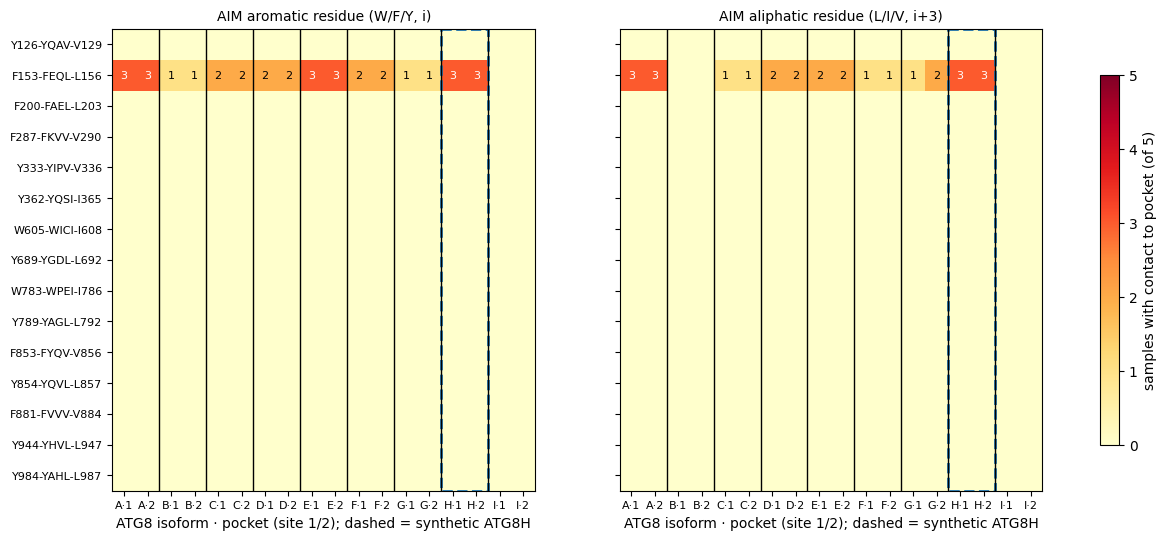

In [3]:
def heat(ax, df, title):
    im = ax.imshow(df.values, cmap="YlOrRd", vmin=0, vmax=N_SAMPLES, aspect="auto")
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels([f"{a[-1]}·{s}" for a, s in df.columns], fontsize=8)
    ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index, fontsize=8)
    for k in range(2, df.shape[1], 2): ax.axvline(k - .5, color="k", lw=1)
    for (i, j), v in np.ndenumerate(df.values):
        if v: ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v >= 3 else "black")
    # synthetic ATG8H columns
    h = [j for j, (a, _) in enumerate(df.columns) if a == "ATG8H"]
    ax.add_patch(plt.Rectangle((h[0] - .5, -.5), 2, df.shape[0], fill=False, ec="tab:blue", lw=2, ls="--"))
    ax.set_title(title, fontsize=10); ax.set_xlabel("ATG8 isoform · pocket (site 1/2); dashed = synthetic ATG8H")
    return im

fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
heat(axs[0], arom, "AIM aromatic residue (W/F/Y, i)")
im = heat(axs[1], aliph, "AIM aliphatic residue (L/I/V, i+3)")
fig.colorbar(im, ax=axs, label=f"samples with contact to pocket (of {N_SAMPLES})", shrink=.8)
plt.show()

## Both anchors in the pocket

A window counts as supported in a sample when its aromatic **and** aliphatic residue both contact the (union of site 1/2) pocket in the *same* sample.

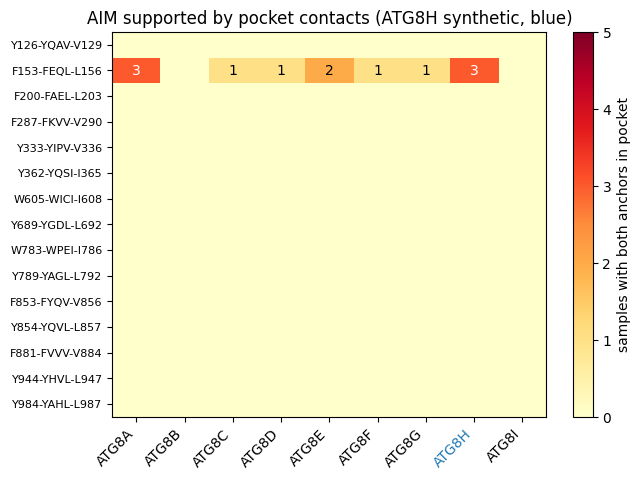

In [4]:
rows = {}
for a in ATG8:
    p = contacts[a]; res = pocket_res.get((a, "1"), set()) | pocket_res.get((a, "2"), set())
    r = []
    for w in win.itertuples():
        ok = [s for s in p["sample"].unique()
              if p[(p["sample"] == s) & (p.resnr == w.arom) & p.resnr_lig.isin(res)].shape[0]
              and p[(p["sample"] == s) & (p.resnr == w.aliph) & p.resnr_lig.isin(res)].shape[0]]
        r.append(len(ok))
    rows[a] = r
both = pd.DataFrame(rows, index=win.label)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(both.values, cmap="YlOrRd", vmin=0, vmax=N_SAMPLES, aspect="auto")
ax.set_xticks(range(both.shape[1])); ax.set_xticklabels(both.columns, rotation=45, ha="right")
ax.set_yticks(range(both.shape[0])); ax.set_yticklabels(both.index, fontsize=8)
for (i, j), v in np.ndenumerate(both.values):
    if v: ax.text(j, i, v, ha="center", va="center", color="white" if v >= 3 else "black")
ax.get_xticklabels()[list(ATG8).index("ATG8H")].set_color("tab:blue")
fig.colorbar(im, label="samples with both anchors in pocket"); ax.set_title("AIM supported by pocket contacts (ATG8H synthetic, blue)")
plt.show()

## Residue-level view for one window
Which pocket residue each anchor touches (samples of 5). Change `WINDOW`.

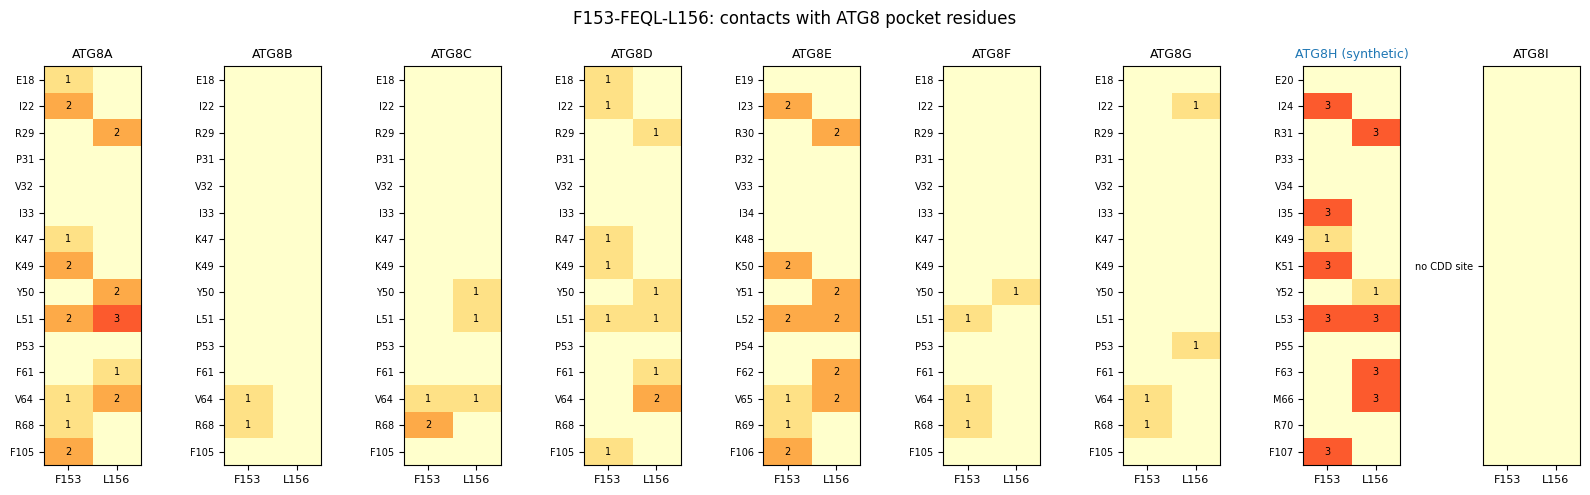

In [5]:
WINDOW = "F153-FEQL-L156"
w = win[win.label == WINDOW].iloc[0]
fig, axs = plt.subplots(1, len(ATG8), figsize=(16, 5), sharey=False)
for ax, (a, _) in zip(axs, ATG8.items()):
    p = contacts[a]
    res = sorted(pocket_res.get((a, "1"), set()) | pocket_res.get((a, "2"), set()))
    seqs = "".join(l.strip() for l in open(ROOT / f"data/sequences/{ATG8[a]}.fasta") if not l.startswith(">"))
    M = np.array([[p[(p.resnr == pos) & (p.resnr_lig == r)]["sample"].nunique() for pos in (w.arom, w.aliph)] for r in res]) if res else np.zeros((1, 2), int)
    ax.imshow(M, cmap="YlOrRd", vmin=0, vmax=N_SAMPLES, aspect="auto")
    ax.set_xticks([0, 1]); ax.set_xticklabels([f"{w.aim[0]}{w.arom}", f"{w.aim[3]}{w.aliph}"], fontsize=8)
    ax.set_yticks(range(len(res)) if res else [0]); ax.set_yticklabels([f"{seqs[r-1]}{r}" for r in res] if res else ["no CDD site"], fontsize=7)
    for (i, j), v in np.ndenumerate(M):
        if v: ax.text(j, i, v, ha="center", va="center", fontsize=7)
    ax.set_title(a + (" (synthetic)" if a == "ATG8H" else ""), fontsize=9, color="tab:blue" if a == "ATG8H" else "k")
plt.suptitle(f"{WINDOW}: contacts with ATG8 pocket residues"); plt.tight_layout(); plt.show()